<a href="https://colab.research.google.com/github/yadavrishikesh/MA-563-Statistical-Computation-and-Simulation-/blob/main/code/module4/Unit4_practice.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
import scipy.stats as stats
from scipy.special import beta as beta_func
from scipy.stats import beta
from scipy.optimize import minimize
from scipy.stats import norm

## Problem 1:
A new drug is tested on $n$ patients and $y$ respond, with true response probability $\theta \in (0,1)$.
* **Prior:** $\theta \sim \text{Beta}(a, b) \implies p(\theta) = \frac{\theta^{a-1}(1-\theta)^{b-1}}{B(a, b)}$
* **Normalised Likelihood:** $L(\theta) \propto \theta^y(1-\theta)^{n-y}$ *(normalised so total area $= 1$)*
* **Posterior:** $\theta \mid y \sim \text{Beta}(a + y,\, b + n - y)$

**What to Do:**
1. Write `prior_fn`, `normalised_likelihood_fn`, and `posterior_fn`.
2. Compute and save `prior_y`, `lik_y`, and `post_y` across the $3 \times 3$ `scenarios` grid of $(n, y, a, b)$ and by plotting, observe how sample size and prior beliefs shift the posterior.
3. **Summarise the Posterior:** For a single scenario $(n, y, a, b)$, compute the posterior point summaries (mean, median, mode), uncertainty measures (standard deviation, 95% equal-tailed CrI, 95% HPD CrI), and tail probability $P(\theta > 0.5 \mid y)$, then run the plotting cell to visualise them.


In [ ]:
# 1. DEFINE SCENARIOS: (n, y, a, b)
scenarios = [
    [(20, 7, 2, 2),      (20, 7, 8, 2),      (20, 7, 2, 8)],
    [(60, 26, 2, 5),     (60, 26, 10, 3),    (60, 26, 3, 12)],
    [(250, 100, 2, 3),(250, 100, 15, 5),   (250, 100, 5, 20)]
]

# 2. DEFINE THETA GRID
theta = np.linspace(0.0001, 0.9999, 1000)

# 3. WRITE THE DISTRIBUTION FUNCTIONS
def prior_fn(theta, a, b):
    return (theta**(a - 1) * (1 - theta)**(b - 1)) / beta_func(a, b)

def normalised_likelihood_fn(theta, n, y):
    raw_lik = (theta**y) * ((1 - theta)**(n - y))
    area = np.trapezoid(raw_lik, theta)
    return raw_lik / area

def posterior_fn(theta, n, y, a, b):
    a_post = a + y
    b_post = b + n - y
    return (theta**(a_post - 1) * (1 - theta)**(b_post - 1)) / beta_func(a_post, b_post)

# 4. COMPUTE & SAVE THE CURVES FOR ALL 9 SCENARIOS
plot_data = []  # Stores computed arrays for each subplot

for r in range(3):
    row_results = []
    for c in range(3):
        n, y, a, b = scenarios[r][c]

        # compute and save the curves here
        prior_y = prior_fn(theta, a, b)
        lik_y = normalised_likelihood_fn(theta, n, y)
        post_y = posterior_fn(theta, n, y, a, b)

        row_results.append({
            "n": n, "y": y, "a": a, "b": b,
            "prior_y": prior_y,
            "lik_y": lik_y,
            "post_y": post_y
        })
    plot_data.append(row_results)


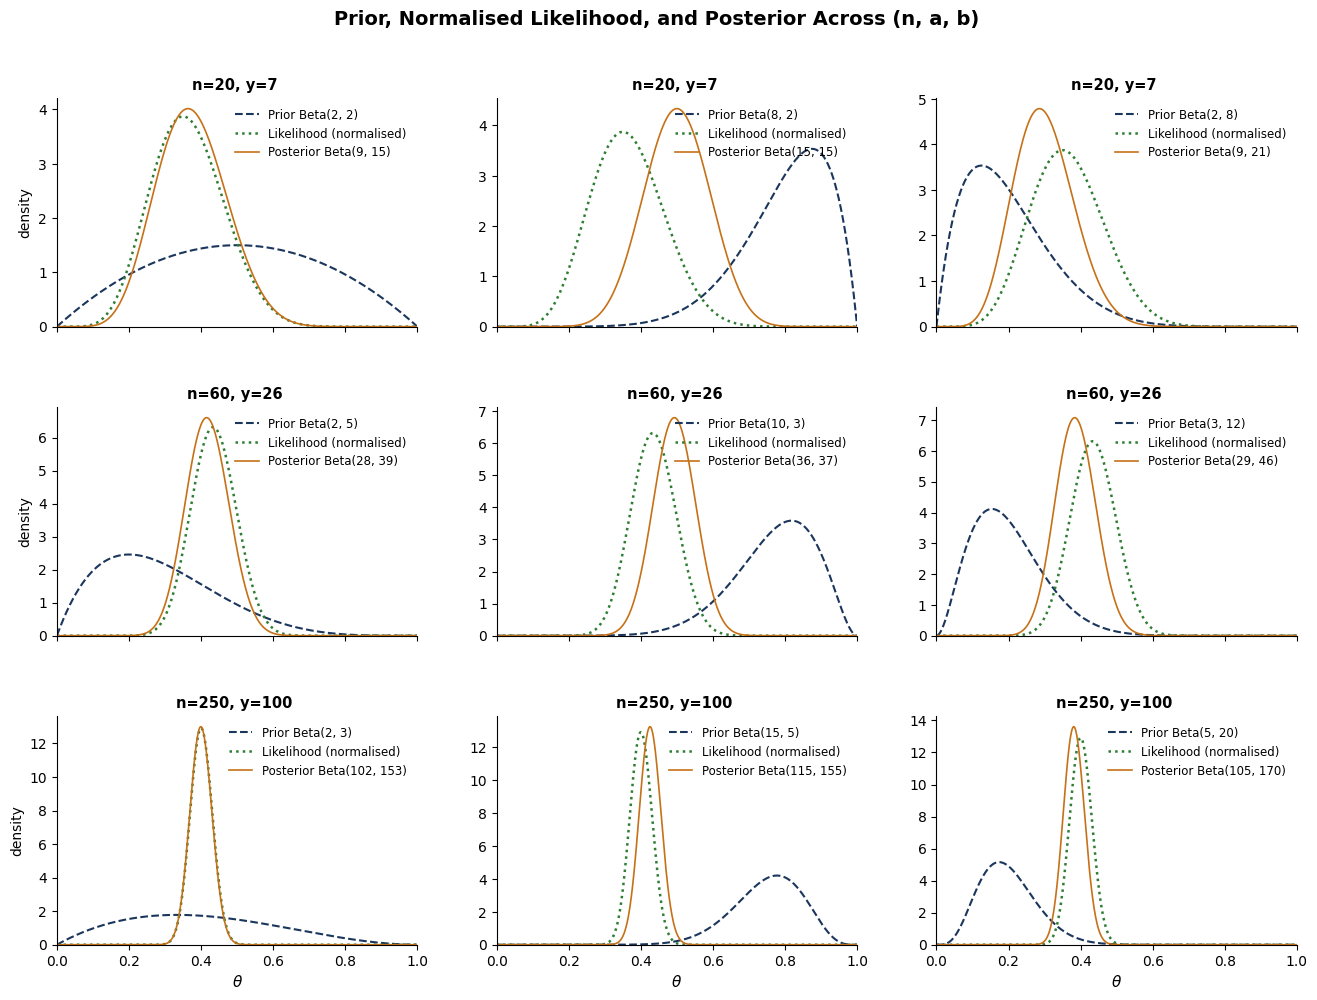

In [ ]:
# =====================================================================
# DO NOT EDIT BELOW THIS LINE — PURE PLOTTING CODE
# =====================================================================

fig, axes = plt.subplots(nrows=3, ncols=3, figsize=(16, 11), sharex=True)
plt.subplots_adjust(hspace=0.35, wspace=0.22)

for r in range(3):
    for c in range(3):
        cell = plot_data[r][c]
        n, y, a, b = cell["n"], cell["y"], cell["a"], cell["b"]
        ax = axes[r, c]

        # Plot the arrays saved by you
        ax.plot(theta, cell["prior_y"], color="#1b365d", linestyle="--", lw=1.5,
                label=f"Prior Beta({a}, {b})")
        ax.plot(theta, cell["lik_y"], color="#2e7d32", linestyle=":", lw=1.8,
                label="Likelihood (normalised)")
        ax.plot(theta, cell["post_y"], color="#c67117", linestyle="-", lw=1.2,
                label=f"Posterior Beta({a+y}, {b+n-y})")

        # Slide styling
        ax.spines["top"].set_visible(False)
        ax.spines["right"].set_visible(False)
        ax.set_xlim(0, 1)
        ax.set_ylim(bottom=0)
        ax.set_title(f"n={n}, y={y} ", fontsize=10.5, fontweight="bold")
        ax.legend(loc="upper right", frameon=False, fontsize=8.5)

        if c == 0:
            ax.set_ylabel("density", fontsize=10)
        if r == 2:
            ax.set_xlabel(r"$\theta$", fontsize=11)

fig.suptitle("Prior, Normalised Likelihood, and Posterior Across (n, a, b)",
             fontsize=14, fontweight="bold", y=0.96)
plt.show()


In [ ]:
# 1. CHOSEN SCENARIO FROM GRID: (n=60, y=26, a=2, b=5) -> Posterior Beta(28, 39)
a_post, b_post = 28, 39

# 2. POINT SUMMARIES & SD
mean = a_post / (a_post + b_post)
median = beta.ppf(0.5, a_post, b_post)
mode = (a_post - 1) / (a_post + b_post - 2)
sd = np.sqrt((a_post * b_post) / ((a_post + b_post)**2 * (a_post + b_post + 1)))

# 3. 95% CREDIBLE INTERVALS & TAIL PROBABILITY
ci_equal = beta.ppf([0.025, 0.975], a_post, b_post)

res = minimize(lambda p: beta.ppf(p + 0.95, a_post, b_post) - beta.ppf(p, a_post, b_post),
               x0=0.025, bounds=[(0, 0.05)])
p_low = res.x[0]  # Extract scalar float from optimizer array
ci_hpd = beta.ppf([p_low, p_low + 0.95], a_post, b_post)

prob_gt_05 = 1 - beta.cdf(0.5, a_post, b_post)

# 4. SAVE FOR PLOTTING & PRINT
summary = {"a": a_post, "b": b_post, "mean": mean, "mode": mode,
           "ci": ci_equal, "prob": prob_gt_05}

print(f"Beta({a_post}, {b_post}) | Mean: {mean:.3f}, Median: {median:.3f}, Mode: {mode:.3f}, SD: {sd:.3f}")
print(f"95% Equal CrI: [{ci_equal[0]:.3f}, {ci_equal[1]:.3f}] | 95% HPD CrI: [{ci_hpd[0]:.3f}, {ci_hpd[1]:.3f}]")
print(f"P(theta > 0.5 | y) = {prob_gt_05:.3f}")


Beta(28, 39) | Mean: 0.418, Median: 0.417, Mode: 0.415, SD: 0.060
95% Equal CrI: [0.303, 0.537] | 95% HPD CrI: [0.302, 0.535]
P(theta > 0.5 | y) = 0.088


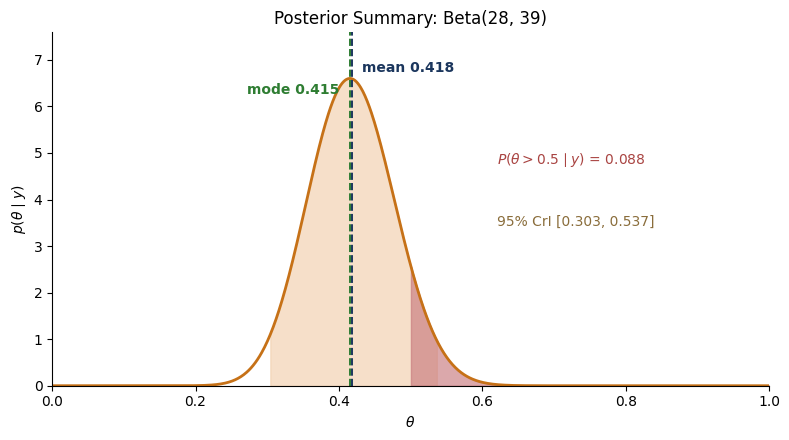

In [ ]:
# =====================================================================
# DO NOT EDIT
# =====================================================================
theta = np.linspace(0.0001, 0.9999, 1000)
pdf = beta.pdf(theta, summary["a"], summary["b"])

fig, ax = plt.subplots(figsize=(8, 4.5))
ax.plot(theta, pdf, color="#c67117", lw=2)

# Shade 95% CrI and P(theta > 0.5 | y)
lo, hi = summary["ci"]
ax.fill_between(theta[(theta >= lo) & (theta <= hi)], pdf[(theta >= lo) & (theta <= hi)], color="#f3d2b3", alpha=0.7)
ax.fill_between(theta[theta >= 0.5], pdf[theta >= 0.5], color="#c97a7e", alpha=0.65)

# Mode & Mean lines + labels
ax.axvline(summary["mode"], color="#2e7d32", ls="--", lw=1.4)
ax.text(summary["mode"] - 0.015, max(pdf)*0.95, f"mode {summary['mode']:.3f}", color="#2e7d32", ha="right", fontweight="bold")

ax.axvline(summary["mean"], color="#1b365d", ls="--", lw=1.4)
ax.text(summary["mean"] + 0.015, max(pdf)*1.02, f"mean {summary['mean']:.3f}", color="#1b365d", ha="left", fontweight="bold")

ax.text(0.62, max(pdf)*0.72, f"$P(\\theta > 0.5 \\mid y)$ = {summary['prob']:.3f}", color="#a94442")
ax.text(0.62, max(pdf)*0.52, f"95% CrI [{lo:.3f}, {hi:.3f}]", color="#8a6d3b")

ax.spines[["top", "right"]].set_visible(False)
ax.set(xlim=(0, 1), ylim=(0, max(pdf)*1.15), xlabel=r"$\theta$", ylabel=r"$p(\theta \mid y)$",
       title=f"Posterior Summary: Beta({summary['a']}, {summary['b']})")
plt.tight_layout()
plt.show()


## Problem 2

A sensor has prior mean $\mu_0 = 10$ and prior SD $\tau_0 = 2$. We take $n$ readings with known measurement SD $\sigma = 3$ and sample mean $\bar{y} = 13$ ($\widehat{\mu}_{\text{MLE}} = \bar{y}$).

* **Prior:** $\mu \sim \mathcal{N}(\mu_0, \tau_0^2)$
* **Likelihood (normalised):** $\mathcal{N}(\bar{y},\, \sigma^2 / n)$
* **Posterior:** $\mu \mid y \sim \mathcal{N}(\mu_n, \tau_n^2)$, where:
  $$\tau_n^2 = \left(\frac{1}{\tau_0^2} + \frac{n}{\sigma^2}\right)^{-1}, \qquad \mu_n = w_n\,\mu_0 + (1 - w_n)\,\widehat{\mu}_{\text{MLE}}, \qquad w_n = \frac{\sigma^2}{\sigma^2 + n\tau_0^2}$$

**What to Do:**
1. Write functions to compute the prior weight $w_n$, posterior parameters $(\mu_n, \tau_n^2)$, and the three Normal densities (`prior_y`, `lik_y`, `post_y`).
2. Run across sample sizes, save the results and observe how posterior changes with increase in sample sizes.



In [ ]:
# 1. FIXED PARAMETERS FROM SENSOR CALIBRATION SLIDE
mu_0, tau_0 = 10.0, 2.0      # Prior mean and SD
sigma, y_bar = 3.0, 13.0     # Known data SD and sample mean (MLE)
n_values =   [5, 15, 30, 70]    # 4 sample sizes
# Grid of mu values
mu_grid = np.linspace(2, 20, 1000)

# 2. WRITE THE POSTERIOR PARAMETER & DENSITY FUNCTIONS
def posterior_params_fn(n, mu_0, tau_0, sigma, y_bar):
    """Returns (w_n, mu_n, tau_n_sq) using precision weighting."""
    w_n = (sigma**2) / (sigma**2 + n * (tau_0**2))
    tau_n_sq = 1.0 / ((1.0 / tau_0**2) + (n / sigma**2))
    mu_n = w_n * mu_0 + (1.0 - w_n) * y_bar
    return w_n, mu_n, tau_n_sq

def normal_pdf_fn(x, mean, sd):
    """Returns Normal density N(mean, sd^2)."""
    return norm.pdf(x, loc=mean, scale=sd)

# 3. COMPUTE & SAVE CURVES FOR ALL 4 SAMPLE SIZES
plot_data = []
for n in n_values:
    w_n, mu_n, tau_n_sq = posterior_params_fn(n, mu_0, tau_0, sigma, y_bar)
    tau_n = np.sqrt(tau_n_sq)
    lik_sd = sigma / np.sqrt(n)

    plot_data.append({
        "n": n, "w_n": w_n, "mu_0": mu_0, "tau_0": tau_0,
        "y_bar": y_bar, "lik_var": sigma**2 / n,
        "mu_n": mu_n, "tau_n": tau_n,
        "prior_y": normal_pdf_fn(mu_grid, mu_0, tau_0),
        "lik_y":   normal_pdf_fn(mu_grid, y_bar, lik_sd),
        "post_y":  normal_pdf_fn(mu_grid, mu_n, tau_n)
    })
    print(f"n = {n:3d} | w_n = {w_n:.3f} | Data weight (1-w_n) = {1-w_n:.3f} | mu_n = {mu_n:.2f} (MLE = {y_bar})")


n =   5 | w_n = 0.310 | Data weight (1-w_n) = 0.690 | mu_n = 12.07 (MLE = 13.0)
n =  15 | w_n = 0.130 | Data weight (1-w_n) = 0.870 | mu_n = 12.61 (MLE = 13.0)
n =  30 | w_n = 0.070 | Data weight (1-w_n) = 0.930 | mu_n = 12.79 (MLE = 13.0)
n =  70 | w_n = 0.031 | Data weight (1-w_n) = 0.969 | mu_n = 12.91 (MLE = 13.0)


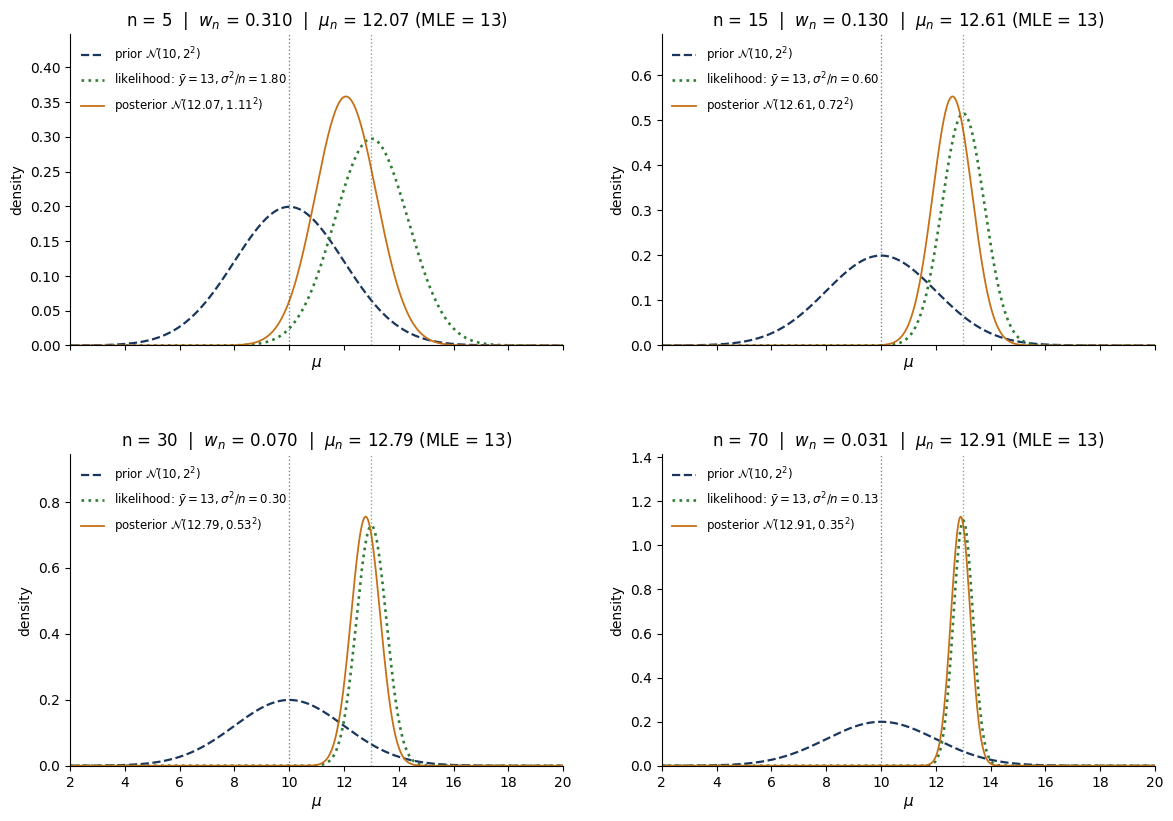

In [ ]:
# =====================================================================
# DO NOT EDIT BELOW THIS LINE — PURE PLOTTING CODE (2x2 DISTRIBUTION GRID)
# =====================================================================
fig, axes = plt.subplots(2, 2, figsize=(14, 9.5), sharex=True)
plt.subplots_adjust(hspace=0.35, wspace=0.20)

for idx, ax in enumerate(axes.flat):
    d = plot_data[idx]

    ax.plot(mu_grid, d["prior_y"], color="#1b365d", ls="--", lw=1.6,
            label=rf"prior $\mathcal{{N}}({d['mu_0']:.0f}, {d['tau_0']:.0f}^2)$")
    ax.plot(mu_grid, d["lik_y"], color="#2e7d32", ls=":", lw=1.9,
            label=rf"likelihood: $\bar{{y}}={d['y_bar']:.0f}, \sigma^2/n={d['lik_var']:.2f}$")
    ax.plot(mu_grid, d["post_y"], color="#c67117", ls="-", lw=1.3,
            label=rf"posterior $\mathcal{{N}}({d['mu_n']:.2f}, {d['tau_n']:.2f}^2)$")

    # Vertical reference lines for Prior Mean (10) and MLE (13)
    ax.axvline(d["mu_0"], color="#1b365d", ls=":", lw=1, alpha=0.6)
    ax.axvline(d["y_bar"], color="#2e7d32", ls=":", lw=1, alpha=0.6)

    ax.spines[["top", "right"]].set_visible(False)
    ax.set(xlim=(2, 20), ylim=(0, max(d["post_y"]) * 1.25), ylabel="density",
           title=f"n = {d['n']}  |  $w_n$ = {d['w_n']:.3f}  |  $\\mu_n$ = {d['mu_n']:.2f} (MLE = {d['y_bar']:.0f})")
    ax.legend(loc="upper left", frameon=False, fontsize=8.5)

for ax in axes.flat:
    ax.set_xlabel(r"$\mu$", fontsize=11)

plt.show()


## Problem 3: Metropolis

Simulate from $\pi(\theta) = \mathcal{N}(0, 1)$ using a random-walk proposal $\theta' = \theta + \varepsilon$, where $\varepsilon \sim \mathcal{N}(0, s^2)$, for different sample sizes.

**What to Do:**
1. Implement `log_q_fn`, `metropolis_sampler`, and `compute_ess`.
2. Loop over all `s` values in `step_sizes` ($20{,}000$ iterations each, $1{,}000$ burn-in) and store the acceptance rates, ESS values, and chains in `mh_results`. Observe step size and acceptance rate in plots.


In [ ]:
# 1. PARAMETERS & STEP SIZES TO EXPLORE
np.random.seed(42)
n_iter = 20000
burn_in = 1000
theta_init = 3.0
step_sizes = [0.1,0.5,1,2.4,5,25]

# 2. WRITE LOG-TARGET, METROPOLIS SAMPLER, AND ESS FUNCTIONS
def log_q_fn(theta):
    """Unnormalised log-density of N(0, 1): log q(theta) = -0.5 * theta^2."""
    return -0.5 * (theta ** 2)

def metropolis_sampler(n_iter, theta_init, s):
    """Runs Random-Walk MH with proposal theta' = theta + eps, eps ~ N(0, s^2)."""
    chain = np.zeros(n_iter)
    chain[0] = theta_init
    accepted = 0

    for t in range(n_iter - 1):
        theta_curr = chain[t]
        theta_prop = theta_curr + np.random.normal(0.0, s)

        log_diff = log_q_fn(theta_prop) - log_q_fn(theta_curr)
        if np.log(np.random.uniform(0.0, 1.0)) <= log_diff:
            chain[t + 1] = theta_prop
            accepted += 1
        else:
            chain[t + 1] = theta_curr

    accept_rate = accepted / (n_iter - 1)
    return chain, accept_rate

def compute_ess(samples):
    """Computes Effective Sample Size (ESS) using positive initial monotone autocorrelation."""
    n = len(samples)
    centered = samples - np.mean(samples)
    var = np.var(samples)
    acf = np.correlate(centered, centered, mode="full")[n - 1:] / (n * var)

    tau = 1.0
    for k in range(1, n // 2):
        if acf[k] <= 0:
            break
        tau += 2.0 * acf[k]
    return n / tau

# 3. RUN SWEEP ACROSS ALL 14 STEP SIZES & SAVE RESULTS
mh_results = []
print(f"{'Step size (s)':<14} | {'Accept Rate':<12} | {'ESS (19k draws)':<15}")
print("-" * 47)

for s in step_sizes:
    chain, acc = metropolis_sampler(n_iter, theta_init, s)
    post_draws = chain[burn_in:]
    ess = compute_ess(post_draws)

    mh_results.append({
        "s": s,
        "chain": chain,
        "post_draws": post_draws,
        "accept_rate": acc,
        "ess": ess
    })
    print(f"s = {s:<10} | {acc:<12.3f} | {ess:<15.0f}")


Step size (s)  | Accept Rate  | ESS (19k draws)
-----------------------------------------------
s = 0.1        | 0.966        | 51             
s = 0.5        | 0.843        | 932            
s = 1          | 0.704        | 2009           
s = 2.4        | 0.444        | 4237           
s = 5          | 0.246        | 2763           
s = 25         | 0.053        | 714            


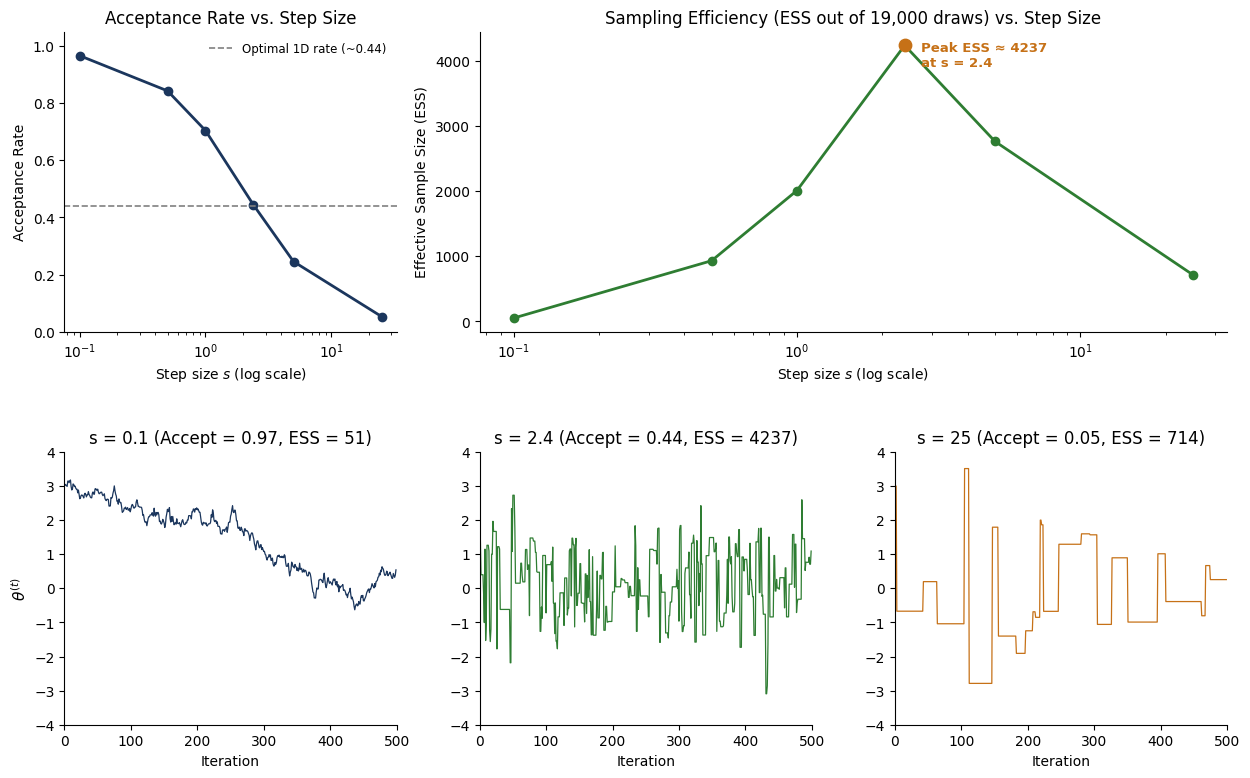

In [ ]:
# =====================================================================
# DO NOT EDIT BELOW THIS LINE — PURE PLOTTING CODE (14 STEP SIZE SWEEP)
# =====================================================================
s_vals = [r["s"] for r in mh_results]
acc_vals = [r["accept_rate"] for r in mh_results]
ess_vals = [r["ess"] for r in mh_results]

# Automatically pick smallest, best-ESS, and largest step sizes for trace comparison
best_idx = int(np.argmax(ess_vals))
showcase_indices = [0, best_idx, len(mh_results) - 1]
showcase_colors = ["#1b365d", "#2e7d32", "#c67117"]

fig = plt.figure(figsize=(15, 9))
gs = fig.add_gridspec(2, 3, height_ratios=[1.1, 1], hspace=0.42, wspace=0.25)

# Top-Left (spans 1.5 cols): Acceptance Rate vs Step Size (log x-axis)
ax_acc = fig.add_subplot(gs[0, :1])
ax_acc.plot(s_vals, acc_vals, marker="o", color="#1b365d", lw=2)
ax_acc.axhline(0.44, color="gray", ls="--", lw=1.2, label="Optimal 1D rate (~0.44)")
ax_acc.set_xscale("log")
ax_acc.spines[["top", "right"]].set_visible(False)
ax_acc.set(xlabel="Step size $s$ (log scale)", ylabel="Acceptance Rate",
           ylim=(0, 1.05), title="Acceptance Rate vs. Step Size")
ax_acc.legend(loc="upper right", frameon=False, fontsize=8.5)

# Top-Right (spans 2 cols): Effective Sample Size (ESS) vs Step Size (log x-axis)
ax_ess = fig.add_subplot(gs[0, 1:])
ax_ess.plot(s_vals, ess_vals, marker="o", color="#2e7d32", lw=2)
best_s, best_ess = s_vals[best_idx], ess_vals[best_idx]
ax_ess.scatter([best_s], [best_ess], color="#c67117", s=80, zorder=5)
ax_ess.annotate(f"Peak ESS ≈ {best_ess:.0f}\nat s = {best_s}",
                (best_s, best_ess), textcoords="offset points", xytext=(12, -15),
                fontweight="bold", color="#c67117", fontsize=9.5)
ax_ess.set_xscale("log")
ax_ess.spines[["top", "right"]].set_visible(False)
ax_ess.set(xlabel="Step size $s$ (log scale)", ylabel="Effective Sample Size (ESS)",
           title="Sampling Efficiency (ESS out of 19,000 draws) vs. Step Size")

# Bottom Row: Trace plots of first 500 iterations for Smallest, Optimal, and Largest s
for col, idx in enumerate(showcase_indices):
    res = mh_results[idx]
    ax = fig.add_subplot(gs[1, col])
    ax.plot(res["chain"][:500], color=showcase_colors[col], lw=0.9)
    ax.spines[["top", "right"]].set_visible(False)
    ax.set(xlim=(0, 500), ylim=(-4, 4), xlabel="Iteration",
           title=f"s = {res['s']} (Accept = {res['accept_rate']:.2f}, ESS = {res['ess']:.0f})")
    if col == 0:
        ax.set_ylabel(r"$\theta^{(t)}$", fontsize=11)


plt.show()


## Problem 4: Gibbs Sampling

**Target:**
$$\begin{pmatrix} X \\ Y \end{pmatrix} \sim \mathcal{N}\!\left(0, \begin{pmatrix} 1 & \rho \\ \rho & 1 \end{pmatrix}\right), \qquad \rho = 0.99$$

**Full Conditionals:**
* $X \mid Y = y \sim \mathcal{N}(\rho y,\, 1 - \rho^2)$
* $Y \mid X = x \sim \mathcal{N}(\rho x,\, 1 - \rho^2)$


**What to Do:**
1. Implement `gibbs_sampler` using the two full conditional distributions above.
2. Run the sampler for $\rho = 0.9$ starting at $(x^{(0)}, y^{(0)}) = (-3, 3)$, discard burn-in, and compute the Effective Sample Size (ESS).
3. Run the plotting cell to observe the axis-parallel staircase trajectory and slow mixing when $\rho = 0.9$.


In [ ]:
# 1. SET PARAMETERS (Try changing rho = 0.9 to 0.2 or 0.8 to compare mixing!)
np.random.seed(42)
rho = 0.9
n_iter = 10000
burn_in = 1000
x_init, y_init = -3.0, 3.0   # Start off the diagonal to see burn-in jump onto the ridge

# 2. WRITE GIBBS SAMPLER & ESS FUNCTIONS
def gibbs_sampler(n_iter, x_init, y_init, rho):
    """Samples (X, Y) using the exact full conditional distributions."""
    x_chain = np.zeros(n_iter)
    y_chain = np.zeros(n_iter)
    x_chain[0], y_chain[0] = x_init, y_init
    cond_sd = np.sqrt(1.0 - rho**2)

    for t in range(1, n_iter):
        # Step 1: X | Y = y^(t-1) ~ N(rho * y, 1 - rho^2)
        x_chain[t] = np.random.normal(loc=rho * y_chain[t - 1], scale=cond_sd)

        # Step 2: Y | X = x^(t) ~ N(rho * x, 1 - rho^2)
        y_chain[t] = np.random.normal(loc=rho * x_chain[t], scale=cond_sd)

    return x_chain, y_chain

def compute_ess(samples):
    """Computes Effective Sample Size (ESS) for a 1D chain."""
    n = len(samples)
    centered = samples - np.mean(samples)
    var = np.var(samples)
    acf = np.correlate(centered, centered, mode="full")[n - 1:] / (n * var)

    tau = 1.0
    for k in range(1, n // 2):
        if acf[k] <= 0:
            break
        tau += 2.0 * acf[k]
    return n / tau

# 3. RUN SAMPLER & SAVE RESULTS FOR PLOTTING
x_chain, y_chain = gibbs_sampler(n_iter, x_init, y_init, rho)
x_post = x_chain[burn_in:]
y_post = y_chain[burn_in:]

ess_x = compute_ess(x_post)
emp_corr = np.corrcoef(x_post, y_post)[0, 1]

gibbs_results = {
    "rho": rho,
    "x_chain": x_chain, "y_chain": y_chain,
    "x_post": x_post, "y_post": y_post,
    "ess_x": ess_x, "emp_corr": emp_corr
}

print(f"Target rho = {rho} | Empirical Corr(X, Y) = {emp_corr:.4f}")
print(f"ESS for X (out of {n_iter - burn_in} post-burn-in draws): {ess_x:.0f}")
print(f"Sample Means: E[X] = {np.mean(x_post):.3f}, E[Y] = {np.mean(y_post):.3f}")


Target rho = 0.9 | Empirical Corr(X, Y) = 0.8972
ESS for X (out of 9000 post-burn-in draws): 940
Sample Means: E[X] = 0.005, E[Y] = 0.006


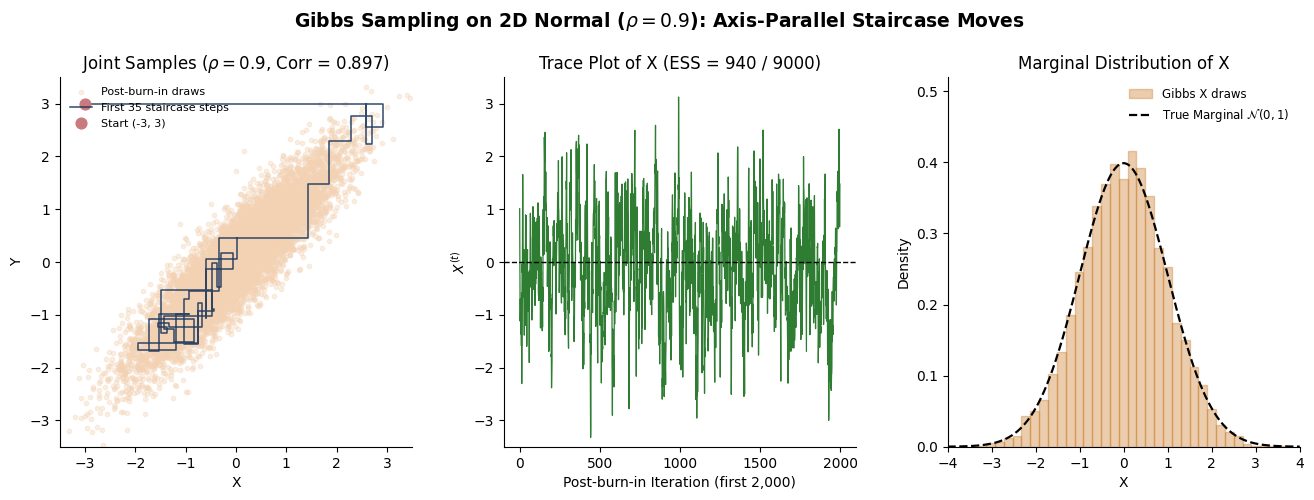

In [ ]:
# =====================================================================
# DO NOT EDIT BELOW THIS LINE — PURE PLOTTING CODE (2D GIBBS DIAGNOSTICS)
# =====================================================================
xc, yc = gibbs_results["x_chain"], gibbs_results["y_chain"]
xp, yp = gibbs_results["x_post"], gibbs_results["y_post"]
r_val = gibbs_results["rho"]

fig, (ax0, ax1, ax2) = plt.subplots(1, 3, figsize=(16, 4.8))
plt.subplots_adjust(wspace=0.26)

# Panel 1: Joint Scatter + First 35 Axis-Parallel (Staircase) Moves
ax0.scatter(xp, yp, color="#f3d2b3", alpha=0.35, s=10, label="Post-burn-in draws")

steps_x, steps_y = [xc[0]], [yc[0]]
for t in range(1, 35):
    # Horizontal move (X | Y), then vertical move (Y | X)
    steps_x.extend([xc[t], xc[t]])
    steps_y.extend([yc[t - 1], yc[t]])

ax0.plot(steps_x, steps_y, color="#1b365d", lw=1.1, alpha=0.9, label="First 35 staircase steps")
ax0.scatter([xc[0]], [yc[0]], color="#c97a7e", s=60, zorder=5, label=f"Start ({xc[0]:.0f}, {yc[0]:.0f})")
ax0.spines[["top", "right"]].set_visible(False)
ax0.set(xlim=(-3.5, 3.5), ylim=(-3.5, 3.5), xlabel="X", ylabel="Y",
        title=f"Joint Samples ($\\rho = {r_val}$, Corr = {gibbs_results['emp_corr']:.3f})")
ax0.legend(loc="upper left", frameon=False, fontsize=8)

# Panel 2: Trace Plot of X (shows slow drift along the narrow ridge)
ax1.plot(xp[:2000], color="#2e7d32", lw=0.9)
ax1.axhline(0, color="black", ls="--", lw=1)
ax1.spines[["top", "right"]].set_visible(False)
ax1.set(ylim=(-3.5, 3.5), xlabel="Post-burn-in Iteration (first 2,000)", ylabel=r"$X^{(t)}$",
        title=f"Trace Plot of X (ESS = {gibbs_results['ess_x']:.0f} / {len(xp)})")

# Panel 3: Marginal Histogram of X vs True N(0, 1)
x_grid = np.linspace(-4, 4, 400)
ax2.hist(xp, bins=35, density=True, color="#c67117", alpha=0.35, edgecolor="#c67117", label="Gibbs X draws")
ax2.plot(x_grid, norm.pdf(x_grid, 0, 1), color="black", ls="--", lw=1.6, label=r"True Marginal $\mathcal{N}(0, 1)$")
ax2.spines[["top", "right"]].set_visible(False)
ax2.set(xlim=(-4, 4), ylim=(0, 0.52), xlabel="X", ylabel="Density",
        title="Marginal Distribution of X")
ax2.legend(loc="upper right", frameon=False, fontsize=8.5)

fig.suptitle(f"Gibbs Sampling on 2D Normal ($\\rho = {r_val}$): Axis-Parallel Staircase Moves",
             fontsize=13.5, fontweight="bold", y=1.02)
plt.show()


## Problem 5: Metropolis-within-Gibbs

We observe $n = 80$ wet-day rainfall amounts $y_1, \dots, y_{80}$ (in mm) at a hill station (true simulation parameters: $\alpha = 0.9$, $\beta = 0.06$). We want to estimate the posterior distribution of $(\alpha, \beta)$ and the **flash-flood risk** $P(Y > 50\text{ mm})$.

* **Model & Priors:**
  $$y_i \mid \alpha, \beta \stackrel{\text{iid}}{\sim} \text{Gamma}(\text{shape}=\alpha,\, \text{rate}=\beta), \qquad \alpha \sim \text{Exp}(1), \qquad \beta \sim \text{Gamma}(1, 1)$$
* **Hybrid Updates (One Sweep):**
  1. **Gibbs Step for $\beta$:** $\beta \mid \alpha, y \sim \text{Gamma}\!\left(1 + n\alpha,\, \text{rate} = 1 + \sum_{i=1}^n y_i\right)$ *(exact draw, no tuning)*.
  2. **Metropolis Step for $\alpha$ (on $\phi = \log \alpha$)**

**What to Do:**
1. Implement `log_cond_alpha` and `mwg_rainfall_sampler` and run $6{,}000$ sweeps ($1{,}000$ burn-in) with step size $s = 0.2$, and compute posterior means, 95% CrIs, and flood risk $P(Y > 50 \mid \alpha^{(m)}, \beta^{(m)})$.
2. Run the plotting cell to reproduce the trace plots, joint posterior scatter, and fitted rainfall density curves from your slides.


In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.special import gammaln
from scipy.stats import gamma as gamma_dist

# 1. SIMULATE HILL-STATION RAINFALL DATA (n = 80, true alpha = 0.9, rate beta = 0.06)
rng = np.random.default_rng(42)
n_obs = 80
y = rng.gamma(shape=0.9, scale=1.0 / 0.06, size=n_obs)

# Precompute sufficient statistics
n, Sy, Sly = len(y), y.sum(), np.log(y).sum()

# 2. DEFINE LOG-CONDITIONAL FOR ALPHA & METROPOLIS-WITHIN-GIBBS SAMPLER
def log_cond_alpha(al, be):
    """Unnormalised log full conditional of alpha given beta and data y."""
    return n * al * np.log(be) - n * gammaln(al) + (al - 1.0) * Sly - al

def mwg_rainfall_sampler(n_sweeps=6000, s=0.2, al_init=1.0, be_init=1.0):
    """Runs Metropolis-within-Gibbs for (alpha, beta) and returns chains + alpha accept rate."""
    A = np.zeros(n_sweeps)
    B = np.zeros(n_sweeps)
    al, be = al_init, be_init
    accepted = 0

    for t in range(n_sweeps):
        # (1) Gibbs step: beta | alpha, y ~ Gamma(1 + n*al, rate = 1 + Sy)
        be = rng.gamma(shape=1.0 + n * al, scale=1.0 / (1.0 + Sy))

        # (2) Metropolis step: alpha | beta, y (random walk on phi = log(alpha))
        phi = np.log(al)
        phi_p = phi + s * rng.standard_normal()
        al_p = np.exp(phi_p)

        logr = (log_cond_alpha(al_p, be) + phi_p) - (log_cond_alpha(al, be) + phi)
        if np.log(rng.uniform()) < logr:
            al = al_p
            accepted += 1

        A[t], B[t] = al, be

    return A, B, accepted / n_sweeps

def compute_ess(samples):
    """Computes Effective Sample Size (ESS) for a 1D chain."""
    m = len(samples)
    centered = samples - np.mean(samples)
    acf = np.correlate(centered, centered, mode="full")[m - 1:] / (m * np.var(samples))
    tau = 1.0
    for k in range(1, m // 2):
        if acf[k] <= 0:
            break
        tau += 2.0 * acf[k]
    return m / tau

# 3. RUN SAMPLER (s = 0.2), DISCARD 1,000 BURN-IN, AND COMPUTE SUMMARIES
n_sweeps, burn_in, step_s = 6000, 1000, 0.2
A_all, B_all, acc_alpha = mwg_rainfall_sampler(n_sweeps=n_sweeps, s=step_s)

A_post = A_all[burn_in:]
B_post = B_all[burn_in:]

# Derived quantities across posterior draws (Slide 90 & Slide 93)
mean_rain = A_post / B_post
prob_gt_50 = gamma_dist.sf(50.0, a=A_post, scale=1.0 / B_post)  # P(Y > 50 | alpha, beta)
return_period = 1.0 / prob_gt_50                              # 50-mm return period

mwg_results = {
    "y": y, "s": step_s, "acc_alpha": acc_alpha,
    "A_post": A_post, "B_post": B_post,
    "ess_a": compute_ess(A_post), "ess_b": compute_ess(B_post),
    "corr": np.corrcoef(A_post, B_post)
}

# Print summary table matching Slide 90


for name, arr in [("shape alpha", A_post), ("rate beta", B_post),
                  ("mean alpha/beta (mm)", mean_rain), ("P(Y > 50 mm)", prob_gt_50),
                  ("Return period 1/P(Y>50)", return_period)]:
    lo, hi = np.percentile(arr, [2.5, 97.5])
    print(f"{name:<24} | post. mean = {np.mean(arr):.3f} | 95% CrI = [{lo:.3f}, {hi:.3f}]")


shape alpha              | post. mean = 1.041 | 95% CrI = [0.777, 1.336]
rate beta                | post. mean = 0.083 | 95% CrI = [0.057, 0.112]
mean alpha/beta (mm)     | post. mean = 12.761 | 95% CrI = [10.299, 15.911]
P(Y > 50 mm)             | post. mean = 0.020 | 95% CrI = [0.006, 0.045]
Return period 1/P(Y>50)  | post. mean = 64.901 | 95% CrI = [22.219, 163.702]


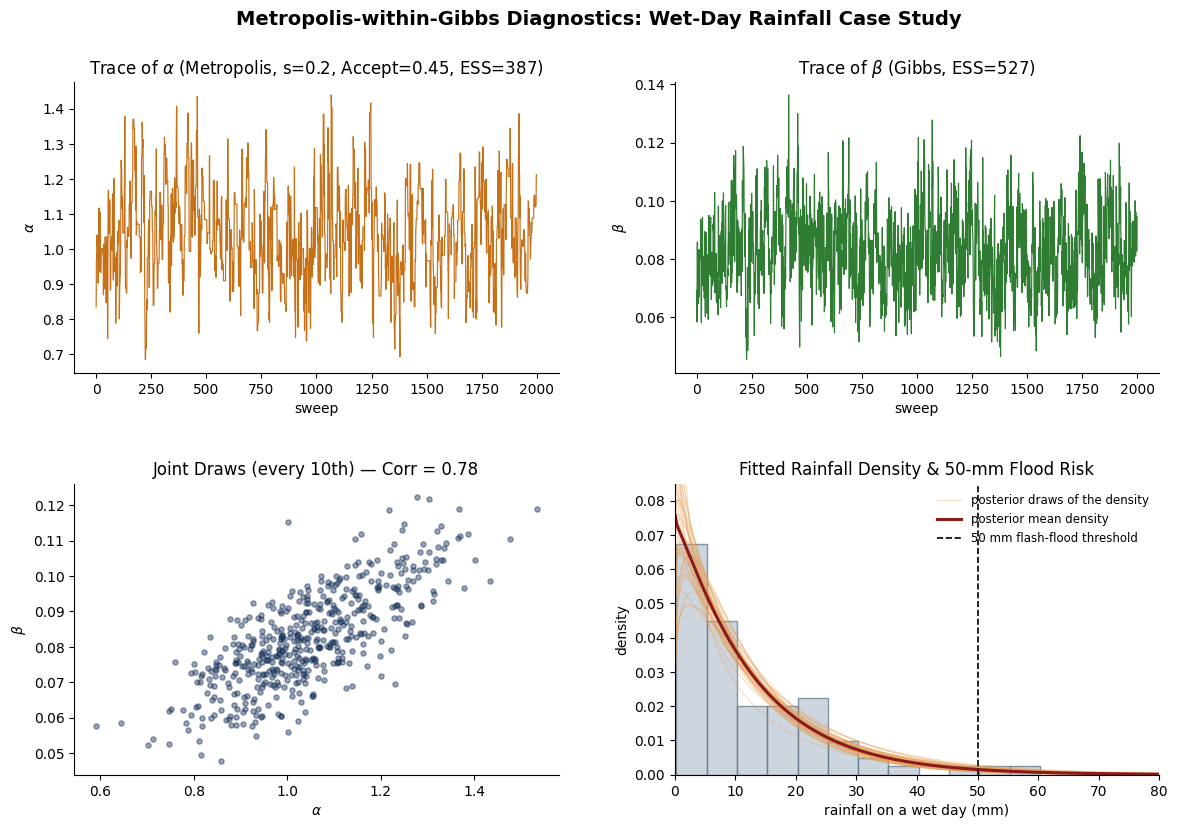

In [ ]:
# =====================================================================
# DO NOT EDIT BELOW THIS LINE — PURE PLOTTING CODE (SLIDES 89 & 90)
# =====================================================================
Ap, Bp = mwg_results["A_post"], mwg_results["B_post"]
y_obs = mwg_results["y"]
corr_val = float(np.corrcoef(Ap, Bp)[0, 1])

fig, ((ax00, ax01), (ax10, ax11)) = plt.subplots(2, 2, figsize=(14, 9))
plt.subplots_adjust(hspace=0.38, wspace=0.24)

# Top-Left: Trace of alpha (first 2,000 post-burn-in sweeps, Slide 89)
ax00.plot(Ap[:2000], color="#c67117", lw=0.85)
ax00.spines[["top", "right"]].set_visible(False)
ax00.set(xlabel="sweep", ylabel=r"$\alpha$",
         title=f"Trace of $\\alpha$ (Metropolis, s={mwg_results['s']}, Accept={mwg_results['acc_alpha']:.2f}, ESS={mwg_results['ess_a']:.0f})")

# Top-Right: Trace of beta (first 2,000 post-burn-in sweeps, Slide 89)
ax01.plot(Bp[:2000], color="#2e7d32", lw=0.85)
ax01.spines[["top", "right"]].set_visible(False)
ax01.set(xlabel="sweep", ylabel=r"$\beta$",
         title=f"Trace of $\\beta$ (Gibbs, ESS={mwg_results['ess_b']:.0f})")

# Bottom-Left: Joint draws (every 10th draw, Slide 89)
ax10.scatter(Ap[::10], Bp[::10], color="#1b365d", alpha=0.45, s=14)
ax10.spines[["top", "right"]].set_visible(False)
ax10.set(xlabel=r"$\alpha$", ylabel=r"$\beta$",
         title=f"Joint Draws (every 10th) — Corr = {corr_val:.2f}")

# Bottom-Right: Histogram + Posterior Draws of Fitted Gamma Density (Slide 90)
x_grid = np.linspace(0.1, 80, 400)
ax11.hist(y_obs, bins=12, density=True, color="#b8c4d0", edgecolor="#5c6f82", alpha=0.7)

# Plot 40 posterior density draws (thin orange curves)
draw_idx = np.linspace(0, len(Ap) - 1, 40, dtype=int)
densities = np.array([gamma_dist.pdf(x_grid, a=Ap[i], scale=1.0 / Bp[i]) for i in draw_idx])
for idx_c, curve in enumerate(densities):
    ax11.plot(x_grid, curve, color="#e69f56", lw=0.8, alpha=0.35,
              label="posterior draws of the density" if idx_c == 0 else "")

# Posterior mean density (thick dark-red curve)
all_densities = np.array([gamma_dist.pdf(x_grid, a=Ap[i], scale=1.0 / Bp[i]) for i in range(0, len(Ap), 10)])
ax11.plot(x_grid, all_densities.mean(axis=0), color="#8b1a1a", lw=2.2, label="posterior mean density")
ax11.axvline(50, color="black", ls="--", lw=1.2, label="50 mm flash-flood threshold")

ax11.spines[["top", "right"]].set_visible(False)
ax11.set(xlim=(0, 80), ylim=(0, 0.085), xlabel="rainfall on a wet day (mm)", ylabel="density",
         title="Fitted Rainfall Density & 50-mm Flood Risk")
ax11.legend(loc="upper right", frameon=False, fontsize=8.5)

fig.suptitle("Metropolis-within-Gibbs Diagnostics: Wet-Day Rainfall Case Study",
             fontsize=14, fontweight="bold", y=0.96)
plt.show()
